# DSP Activity 5: Philippine License Plate Text Extraction

Same workflow as the previous activities (segment -> clean up -> label -> `regionprops`), plus **OCR** to read the plate number.

For every plate the program will:
1. **Detect** the plate (HSV: white background is low saturation + high value)
2. **Extract the text** (plate number and the small text such as `NCR 2026`) using Tesseract OCR
3. **Classify the plate type** from its **color** (HSV) and cross-check it with the **plate number**

| Sample | Plate color (HSV) | Type |
|---|---|---|
| `ABC 1234` | white, black border and letters | **NCR Private Vehicle** |
| `DEF 5678` | yellow background | **Public Utility** |
| `SAA 1234` | white, red border and letters | **Government** |
| `MNO 7890` | white, blue border and letters | **Diplomatic** |
| `NNV 1234` | white, green border and letters | **E-Vehicle** |
| `123DBC` | white, black border, blue band on top | **Region 4** |

**Requirements:** `pip install pytesseract` and the Tesseract-OCR program installed on your computer.
Put `plates.png` and `plate_region4.png` in the same folder as this notebook.

In [1]:
import re
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
from skimage.measure import label, regionprops
from skimage.morphology import disk, opening, closing

# Windows only: uncomment and fix the path if Tesseract is not found
# pytesseract.pytesseract.tesseract_cmd = r'C:\Program Files\Tesseract-OCR\tesseract.exe'

## 5.1 Load the images

plates.png: width 1774px, height 887px
plate_region4.png: width 1660px, height 948px


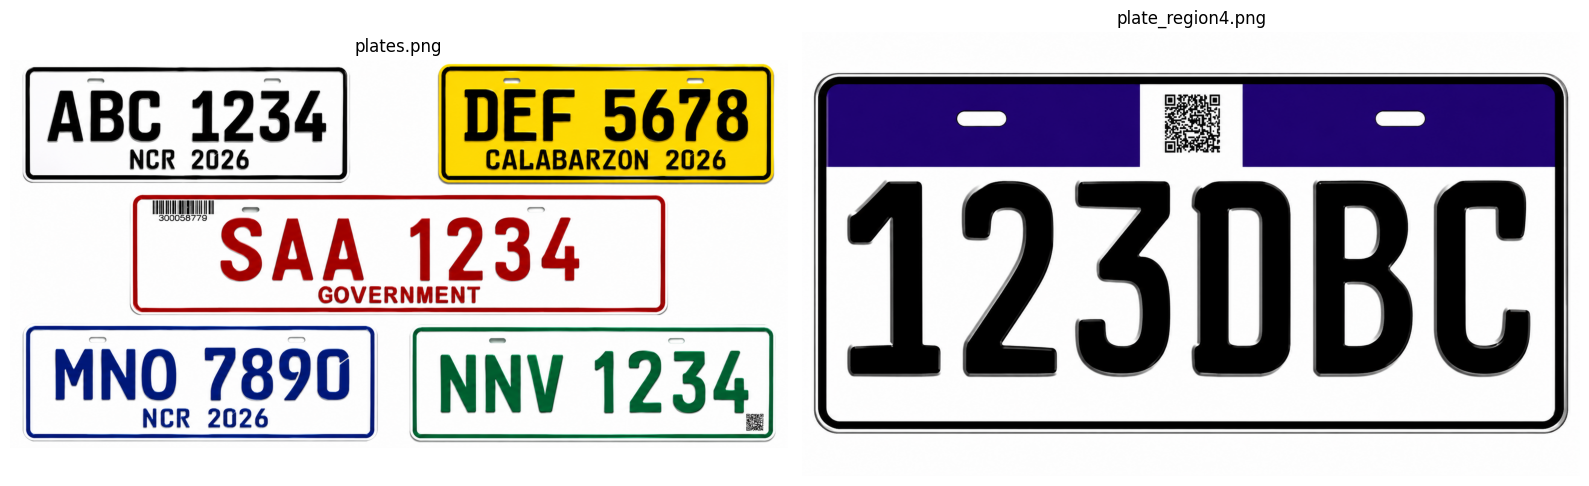

In [2]:
files = ['plates.png', 'plate_region4.png']
images = []
for f in files:
    img = cv2.imread(f)
    if img is None:
        raise FileNotFoundError(f"Image not found: {f}")
    images.append(img)
    print(f"{f}: width {img.shape[1]}px, height {img.shape[0]}px")

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for a, img, f in zip(axs, images, files):
    a.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); a.set_title(f); a.axis("off")
plt.tight_layout()
plt.show()

## 5.2 Detect the plates using HSV

The background is white: **low saturation and high value**. Everything that is *not* background is part of a plate. Then we close small gaps, fill holes, open, and label (same steps as Activities 3 and 4).

plates.png: 5 plate(s) found


plate_region4.png: 1 plate(s) found


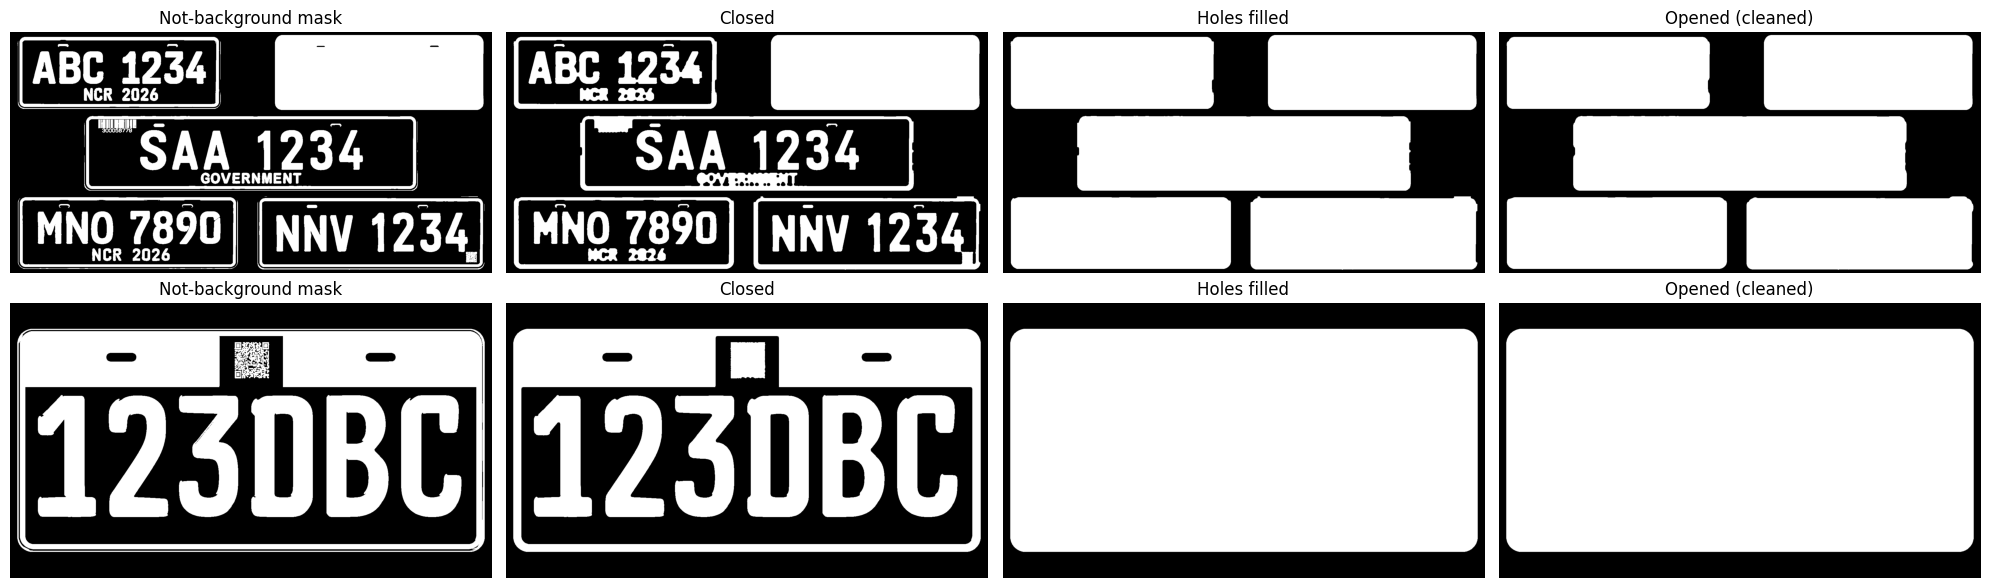

In [3]:
def segment_plates(bgr):
    """Return the intermediate masks and the regionprops of every plate found."""
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    Hm, Sm, Vm = cv2.split(hsv)

    # Background = low saturation AND high brightness
    background = (Sm < 30) & (Vm > 235)
    not_bg = (~background).astype(np.uint8)

    # Close small gaps (the plate border becomes a closed loop)
    closed = closing(not_bg, disk(5)).astype(np.uint8)

    # Fill holes (flood fill from the corner, invert, OR)
    flood = (closed * 255).astype(np.uint8)
    h, w = flood.shape
    mask = np.zeros((h + 2, w + 2), np.uint8)
    cv2.floodFill(flood, mask, (0, 0), 255)
    filled = cv2.bitwise_or(closed * 255, cv2.bitwise_not(flood))

    # Morphological opening
    opened = opening(filled // 255, disk(10)).astype(np.uint8)

    # Label connected components
    lab = label(opened)
    regions = [r for r in regionprops(lab) if r.area > 5000]

    # Reading order: top to bottom, then left to right
    regions.sort(key=lambda r: (r.bbox[0] // 150, r.bbox[1]))
    return [not_bg, closed, filled, opened], regions

fig, axs = plt.subplots(2, 4, figsize=(20, 6))
titles = ["Not-background mask", "Closed", "Holes filled", "Opened (cleaned)"]
all_regions = []
for row, img in enumerate(images):
    steps, regions = segment_plates(img)
    all_regions.append(regions)
    for a, s, t in zip(axs[row], steps, titles):
        a.imshow(s, cmap='gray'); a.set_title(t); a.axis("off")
    print(f"{files[row]}: {len(regions)} plate(s) found")
plt.tight_layout()
plt.show()

## 5.3 Extract the text of one plate (step by step)

Inside a plate:
1. **Crop** the plate and cut away the border.
2. Find the **background color** of the plate (most common color).
3. **Text mask** = pixels that are very different from the background color.
4. Keep the **tall characters** (the plate number) and ignore small things like the barcode, QR code and the small text.
5. Send the black-on-white character image to **Tesseract**.

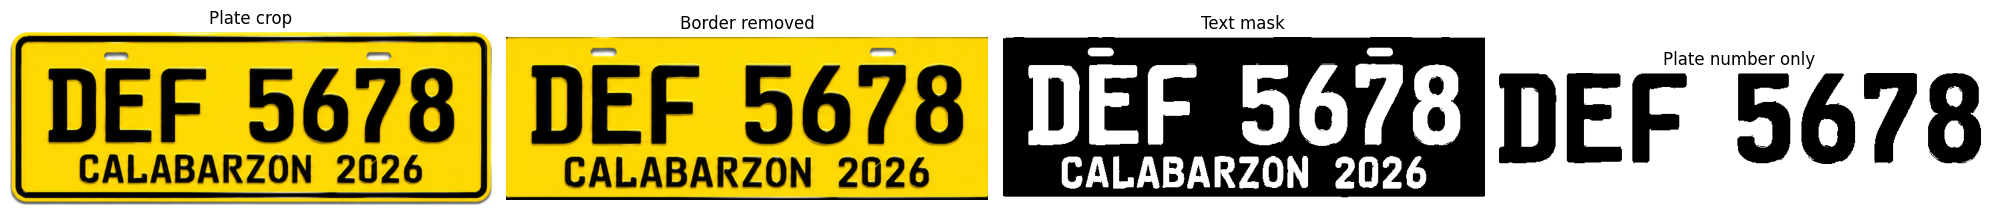

Plate number: DEF5678
Small text  : CALABARZON 2026


In [4]:
def dominant_color(bgr_img):
    """Most common color (BGR) of an image."""
    q = (bgr_img // 32).reshape(-1, 3).astype(int)
    keys = q[:, 0] * 64 + q[:, 1] * 8 + q[:, 2]
    k = np.bincount(keys).argmax()
    return np.median(bgr_img.reshape(-1, 3)[keys == k], axis=0)

def ocr(binary_black_on_white, whitelist=None, psm=7, height=100):
    """Pad, resize and read an image with Tesseract."""
    img = cv2.copyMakeBorder(binary_black_on_white, 30, 30, 30, 30, cv2.BORDER_CONSTANT, value=255)
    scale = height / img.shape[0]
    img = cv2.resize(img, None, fx=scale, fy=scale)
    cfg = f'--psm {psm}'
    if whitelist:
        cfg += f' -c tessedit_char_whitelist={whitelist}'
    return pytesseract.image_to_string(img, config=cfg).strip()

ALNUM = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789'

def extract_text(crop):
    """Return plate number, small text and the images used on the way."""
    h, w = crop.shape[:2]

    # 1) remove the border
    mh, mw = int(0.06 * h), int(0.03 * w)
    inner = crop[mh:h - mh, mw:w - mw]
    ih, iw = inner.shape[:2]

    # 2) background color and 3) text mask
    bg = dominant_color(inner)
    dist = np.linalg.norm(inner.astype(float) - bg, axis=2)
    text_mask = (dist > 90).astype(np.uint8)

    # 4) keep the tall characters (plate number)
    n, lb, st, _ = cv2.connectedComponentsWithStats(text_mask)
    chars = [i for i in range(1, n)
             if st[i, 3] > 0.15 * ih and 0.08 < st[i, 2] / st[i, 3] < 1.5 and st[i, 4] > 0.001 * ih * iw]
    tallest = max(st[i, 3] for i in chars)
    main = [i for i in chars if st[i, 3] > 0.7 * tallest]

    x0 = min(st[i, 0] for i in main); x1 = max(st[i, 0] + st[i, 2] for i in main)
    y0 = min(st[i, 1] for i in main); y1 = max(st[i, 1] + st[i, 3] for i in main)
    main_mask = np.isin(lb, main).astype(np.uint8)
    main_img = 255 - main_mask[y0:y1, x0:x1] * 255

    # 5) OCR of the plate number
    number = ocr(main_img, ALNUM)

    # small text below the plate number (e.g. NCR 2026, GOVERNMENT)
    sub = text_mask[y1:, :]
    n2, lb2, st2, _ = cv2.connectedComponentsWithStats(sub)
    keep = [i for i in range(1, n2) if st2[i, 3] > 0.08 * ih and st2[i, 4] >= 80]
    small = ''
    small_img = None
    if keep:
        sm = np.isin(lb2, keep).astype(np.uint8)
        ys, xs = np.where(sm > 0)
        small_img = 255 - sm[ys.min():ys.max() + 1, xs.min():xs.max() + 1] * 255
        raw = ocr(small_img, height=60)   # no whitelist so the spaces are kept
        small = ' '.join(re.findall(r'[A-Z0-9]+', raw))
        if len(small.replace(' ', '')) < 3:
            small = ''
    return dict(inner=inner, bg=bg, text_mask=text_mask, main_img=main_img,
                number=number, small=small, small_img=small_img)

# --- demo on the yellow plate (DEF 5678) ---
r = all_regions[0][1]
minr, minc, maxr, maxc = r.bbox
crop = images[0][minr:maxr, minc:maxc]
res = extract_text(crop)

fig, axs = plt.subplots(1, 4, figsize=(20, 4))
axs[0].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB));        axs[0].set_title("Plate crop")
axs[1].imshow(cv2.cvtColor(res['inner'], cv2.COLOR_BGR2RGB)); axs[1].set_title("Border removed")
axs[2].imshow(res['text_mask'], cmap='gray');                 axs[2].set_title("Text mask")
axs[3].imshow(res['main_img'], cmap='gray');                  axs[3].set_title("Plate number only")
for a in axs: a.axis("off")
plt.tight_layout()
plt.show()

print("Plate number:", res['number'])
print("Small text  :", res['small'])

## 5.4 Classify the plate type using HSV

Two independent checks:

**By color (HSV, OpenCV ranges H 0-179):**

| Check | Result |
|---|---|
| Yellow background (H 15-35, high S) | Public Utility |
| Red border (H 0-10 or 165-179) | Government |
| Blue border (H 100-130) | Diplomatic |
| Green border (H 40-90) | E-Vehicle |
| Black border + blue band on top (H 100-150) | Region 4 |
| Black border, no band | NCR Private Vehicle |

**By plate number:** `ABC` = NCR Private, `DEF` = Public Utility, `SAA` = Government, `MNO` = Diplomatic, `NNV` = E-Vehicle, and the pattern 3 digits + 3 letters (like `123DBC`) = Region 4.

In [5]:
def classify_by_color(crop, res):
    h, w = crop.shape[:2]
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)

    # Background color of the plate in HSV
    bgh, bgs, bgv = cv2.cvtColor(np.uint8([[res['bg']]]), cv2.COLOR_BGR2HSV)[0, 0]
    if bgs > 150 and 15 <= bgh <= 35:
        return 'Public Utility', (bgh, bgs, bgv)

    # Border color: colored / dark pixels of the outer ring of the plate
    ring = np.zeros((h, w), bool)
    ring[:int(0.05 * h)] = True; ring[-int(0.05 * h):] = True
    ring[:, :int(0.02 * w)] = True; ring[:, -int(0.02 * w):] = True
    px = hsv[ring].astype(int)
    px = px[(px[:, 2] < 200) | (px[:, 1] > 60)]
    rh, rs, rv = np.median(px, axis=0)

    if rs > 100:
        if rh <= 10 or rh >= 165:
            return 'Government', (rh, rs, rv)
        if 100 <= rh <= 130:
            return 'Diplomatic', (rh, rs, rv)
        if 40 <= rh <= 90:
            return 'E-Vehicle', (rh, rs, rv)

    # Black border: look for the blue band on top of the plate
    ihsv = cv2.cvtColor(res['inner'], cv2.COLOR_BGR2HSV)
    top = ihsv[:int(0.2 * ihsv.shape[0])]
    band = (top[..., 0] > 100) & (top[..., 0] < 150) & (top[..., 1] > 100)
    if band.mean() > 0.3:
        return 'Region 4', (rh, rs, rv)
    return 'NCR Private Vehicle', (rh, rs, rv)

def classify_by_text(number):
    prefix_rules = {'ABC': 'NCR Private Vehicle', 'DEF': 'Public Utility',
                    'SAA': 'Government', 'MNO': 'Diplomatic', 'NNV': 'E-Vehicle'}
    if re.fullmatch(r'\d{3}[A-Z]{3}', number):
        return 'Region 4'
    return prefix_rules.get(number[:3], 'Unknown')

def format_number(number):
    # ABC1234 -> ABC 1234, 123DBC stays as it is
    m = re.fullmatch(r'([A-Z]{3})(\d{4})', number)
    return f"{m.group(1)} {m.group(2)}" if m else number

type_colors = {            # box colors (RGB)
    'NCR Private Vehicle': (0, 0, 0),
    'Public Utility':      (230, 160, 0),
    'Government':          (220, 0, 0),
    'Diplomatic':          (0, 0, 255),
    'E-Vehicle':           (0, 150, 0),
    'Region 4':            (90, 0, 160),
}

## 5.5 Run on all plates and show the final result

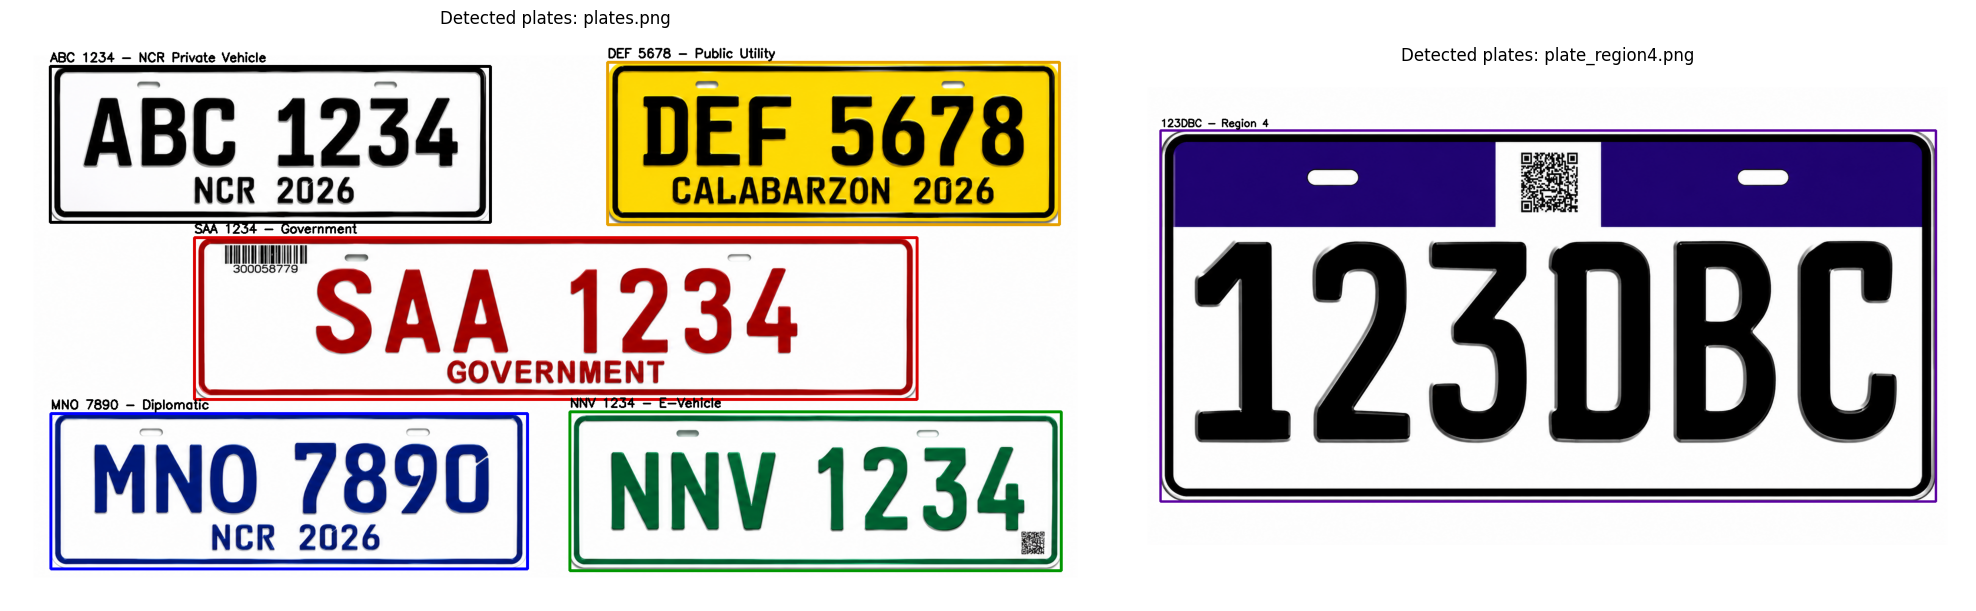

Plate number  Small text        Type (by color)       Type (by number)      Match
----------------------------------------------------------------------------------
ABC 1234      NCR 2026          NCR Private Vehicle   NCR Private Vehicle   OK
DEF 5678      CALABARZON 2026   Public Utility        Public Utility        OK
SAA 1234      GOVERNMENT        Government            Government            OK
MNO 7890      NCR 2026          Diplomatic            Diplomatic            OK
NNV 1234                        E-Vehicle             E-Vehicle             OK
123DBC                          Region 4              Region 4              OK

Total plates detected: 6


In [6]:
results = []
pad = 40
fig, axs = plt.subplots(1, 2, figsize=(20, 6), gridspec_kw={'width_ratios': [1.6, 1.2]})

for k, (img, regions) in enumerate(zip(images, all_regions)):
    out = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    out = cv2.copyMakeBorder(out, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=(255, 255, 255))

    for r in regions:
        minr, minc, maxr, maxc = r.bbox
        crop = img[minr:maxr, minc:maxc]

        res = extract_text(crop)
        number = format_number(res['number'])
        by_color, _ = classify_by_color(crop, res)
        by_text = classify_by_text(res['number'])
        results.append((files[k], number, res['small'], by_color, by_text))

        # draw the box and the label above the plate
        color = type_colors.get(by_color, (255, 0, 255))
        minr, minc, maxr, maxc = minr + pad, minc + pad, maxr + pad, maxc + pad
        cv2.rectangle(out, (minc, minr), (maxc, maxr), color, 3)
        label_text = f"{number} - {by_color}"
        cv2.putText(out, label_text, (minc, minr - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)

    axs[k].imshow(out)
    axs[k].set_title(f"Detected plates: {files[k]}")
    axs[k].axis("off")

plt.tight_layout()
plt.show()

# Summary table
print(f"{'Plate number':<14}{'Small text':<18}{'Type (by color)':<22}{'Type (by number)':<22}Match")
print("-" * 82)
for f, number, small, by_color, by_text in results:
    print(f"{number:<14}{small:<18}{by_color:<22}{by_text:<22}{'OK' if by_color == by_text else 'CHECK'}")
print(f"\nTotal plates detected: {len(results)}")